# Task 2: Player segmentation

รายงาน EDA จากข้อมูลในเครื่อง วันที่ 2 พฤศจิกายน 2026 ไม่มีการฝึกโมเดลใน notebook นี้ ค่าที่เขียนใน Markdown อิง snapshot ที่ตรวจครั้งนี้ หากเปลี่ยนข้อมูลให้สร้างรายงานใหม่และรันทุก cell อีกครั้ง

## 1. Task Overview

จำแนกกลุ่มผู้เล่นเพื่อปรับกิจกรรมและข้อเสนอให้เหมาะกับพฤติกรรม

Target: `segment`. 0=Casual, 1=Grinder, 2=Social, 3=Whale

ไม่พบ metric ทางการในไฟล์ที่ได้รับ แนะนำ macro F1 และ accuracy เป็น local proxy

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'sample_submission.csv').exists())
sys.path.insert(0, str(ROOT))
from shared.eda_utils import (
    TASKS, load_task, quality_table, outlier_table, bounds_table,
    association, strongest_pairs, period_changes, image_inventory, setup_plot,
)
setup_plot()

train, test, target, base = load_task(ROOT, 2)
frame = train if train is not None else test
features = frame.drop(columns=['player_id', target], errors='ignore')

## 2. Dataset Overview

| กลุ่ม | ความหมายตาม data card |
|---|---|
| engagement | play frequency, session duration, playtime และ login |
| spending | ยอดใช้จ่าย ความถี่ซื้อ VIP และ loyalty |
| social/competitive | เพื่อน chat team play rank และ tournament |
| categorical | region, platform, device, payment, language และ tier |
| random_metric_1–3 | data card ระบุว่าเป็น noise |

In [2]:
overview = pd.DataFrame([
    {'split': name, 'rows': len(data), 'columns': data.shape[1],
     'target_available': int(data[target].notna().sum()) if target in data else 0}
    for name, data in [('train', train), ('test', test)] if data is not None
])
display(overview)
display(features.dtypes.astype(str).value_counts().rename('feature_count').to_frame())
with pd.option_context('display.max_rows', None):
    display(features.dtypes.astype(str).to_frame('dtype'))
display(frame.drop(columns='player_id').head(3))

,split,rows,columns,target_available
0,train,104000,46,104000
1,test,25889,45,0


,feature_count
float64,34
str,10


,dtype
play_frequency,float64
avg_session_duration,float64
total_playtime_hours,float64
login_streak,float64
days_since_last_login,float64
total_spending_thb,float64
avg_monthly_spending,float64
spending_frequency,float64
friend_count,float64
team_play_percentage,float64


,play_frequency,avg_session_duration,total_playtime_hours,login_streak,days_since_last_login,total_spending_thb,...,account_status,player_type_tag,engagement_level,loyalty_tier,skill_tier,segment
0,21.0762,NaN,NaN,97.0000,67.1034,"72,431.1806",...,Dormant,Collector,Low,Platinum,Diamond,2
1,7.9091,197.3150,976.4409,103.0000,50.8692,"50,422.0234",...,Active,Social,High,Silver,NaN,3
2,2.5200,23.6043,"1,878.4170",61.0000,74.4772,"9,970.1569",...,Dormant,Collector,Mid,Bronze,Platinum,0


**Findings & Interpretation**

**Findings:** Train มี 104,000 แถว; test มี 25,889 แถว, feature 44 ตัว และ label ที่ใช้ได้ 104,000 แถว

**Interpretation:** ต้องแยกความครบของ feature ออกจากความครบของ label

**ML Implications:** ไม่เติม target ที่หายและไม่ใช้ player_id เป็น predictor

**Recommended Action:** ตรวจ missing และขอบเขตข้อมูลก่อนเลือก preprocessing

## 3. Data Quality Analysis

Duplicate IDs: 0
Duplicate feature rows: 0
Train/test ID overlap: 0
Missing target: 0


,dtype,missing,missing_pct,unique
payment_method,str,31892,30.6654,3
region,str,27146,26.1019,4
account_status,str,8161,7.8471,2
platform,str,8113,7.8010,3
item_type_preference_social,float64,8096,7.7846,93505
item_type_preference_performance,float64,8089,7.7779,91618
random_metric_1,float64,8080,7.7692,95920
skill_tier,str,8074,7.7635,5
random_metric_2,float64,8074,7.7635,95926
avg_match_length,float64,8072,7.7615,95928


,feature,expected_min,expected_max,outside_range
0,play_frequency,0,7.0000,69465
1,peak_concurrent_hours,0,24.0000,74846
2,team_play_percentage,0,100.0000,0
3,total_spending_thb,0,inf,0


,iqr_outliers,observed,outlier_pct
random_metric_3,650,96013,0.6770
chat_activity_score,524,95943,0.5462
rare_items_count,521,96031,0.5425
friend_invites_sent,513,96108,0.5338
speed_of_progression,512,95934,0.5337
total_spending_thb,513,96126,0.5337
tournament_entries,511,95953,0.5326
peak_concurrent_hours,503,95958,0.5242


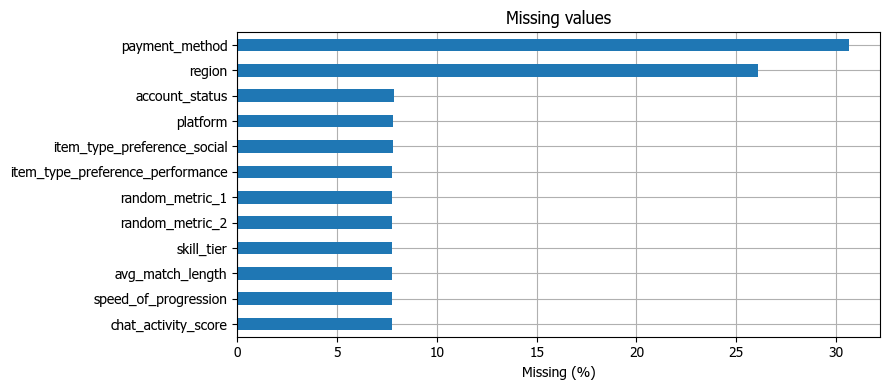

In [3]:
quality = quality_table(features)
display(quality.head(12))
print('Duplicate IDs:', int(frame.player_id.duplicated().sum()))
print('Duplicate feature rows:', int(features.duplicated().sum()))
if train is not None:
    print('Train/test ID overlap:', len(set(train.player_id) & set(test.player_id)))
    print('Missing target:', int(train[target].isna().sum()))
display(bounds_table(frame, 2))
display(outlier_table(features).head(8))
quality.missing_pct.head(12).sort_values().plot.barh(xlabel='Missing (%)', title='Missing values')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Feature missing เฉลี่ย 8.63%; สูงสุด `payment_method` 30.67%; duplicate feature rows 0; พบค่าที่อยู่นอกช่วงตรวจทั้งหมด 144,311 จุด (นับระดับ cell); feature ที่มี IQR outlier สูงสุดคือ `random_metric_3` 0.68%

**Interpretation:** ค่าหลุด IQR เป็น outlier เชิงสถิติ ไม่ยืนยันว่าเป็นข้อมูลผิด ช่วงที่ตรวจมาจากความหมายใน data card และอาจสะท้อนนิยามหรือข้อมูลสังเคราะห์ที่ต่างออกไป

**ML Implications:** ใช้โมเดลรองรับ missing หรือ fit imputer เฉพาะ training fold; ยังไม่ clip ทั้งชุด

**Recommended Action:** ตรวจ feature ที่อยู่นอกช่วงกับนิยามต้นทาง และเก็บ missing indicator เมื่อใช้ imputer

In [4]:
missing_compare = pd.DataFrame({'train_pct': features.isna().mean() * 100,
                                'test_pct': test[features.columns].isna().mean() * 100})
missing_compare['gap_pp'] = missing_compare.test_pct - missing_compare.train_pct
display(missing_compare.sort_values('gap_pp', key=lambda x: x.abs(), ascending=False).head(10))
print('Duplicate test feature rows:', test[features.columns].duplicated().sum())
train_hash = pd.util.hash_pandas_object(features, index=False)
test_hash = pd.util.hash_pandas_object(test[features.columns], index=False)
print('Train/test identical feature row hashes:', len(set(train_hash) & set(test_hash)))

Duplicate test feature rows: 0
Train/test identical feature row hashes: 0


,train_pct,test_pct,gap_pp
competitive_rank,7.6106,7.9995,0.3890
login_streak,7.7096,7.3506,-0.3590
language,7.5827,7.9146,0.3319
days_since_last_login,7.7413,7.4201,-0.3212
payment_method,30.6654,30.9784,0.3130
watches_esports,7.6952,7.4279,-0.2673
engagement_level,7.5327,7.7987,0.2660
play_frequency,7.7221,7.9879,0.2658
vip_tier,7.6923,7.9493,0.2570
achievement_completion_rate,7.7144,7.4588,-0.2557


**Findings & Interpretation**

**Findings:** Missing ใน test เฉลี่ย 8.63%; ช่องว่าง train/test ที่มากสุดคือ `competitive_rank` 0.39 percentage points

**Interpretation:** การเปรียบเทียบนี้ตรวจเฉพาะ missingness และ exact feature rows ยังไม่พิสูจน์ว่าไม่มี distribution shift

**ML Implications:** ใช้ preprocessing ที่รองรับ missing ในทั้งสอง split และหลีกเลี่ยง fit บน test สำหรับ supervised tasks

**Recommended Action:** หากคะแนนจริงต่างจาก holdout มาก ให้ตรวจ feature distribution และรูปแบบเก็บข้อมูลเพิ่มเติม

## 4. Statistical Analysis

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
play_frequency,"95,969.0000",NaN,NaN,NaN,12.1206,7.0674,1.0000,6.4645,11.4201,16.8652,48.7004
avg_session_duration,"96,060.0000",NaN,NaN,NaN,107.3004,54.2504,20.0006,64.0319,102.4522,143.7395,381.2783
total_playtime_hours,"95,997.0000",NaN,NaN,NaN,"1,700.5748",942.4511,100.1183,965.4677,"1,635.5003","2,341.1260","5,992.5901"
login_streak,"95,982.0000",NaN,NaN,NaN,55.0760,35.4274,0.0000,26.0000,52.0000,79.0000,234.0000
days_since_last_login,"95,949.0000",NaN,NaN,NaN,45.9625,20.9245,0.0077,31.2383,45.8294,60.3600,136.2029
total_spending_thb,"96,126.0000",NaN,NaN,NaN,"34,219.6711","22,098.0761",500.4742,"16,335.2284","31,572.3210","49,016.4151","144,500.5773"
avg_monthly_spending,"96,146.0000",NaN,NaN,NaN,"3,306.2621","1,935.8732",100.0521,"1,778.1974","3,163.9231","4,614.3388","12,960.9184"
spending_frequency,"96,092.0000",NaN,NaN,NaN,17.0300,9.6166,1.0000,9.4805,16.2793,23.5704,64.3145
friend_count,"95,948.0000",NaN,NaN,NaN,107.5769,64.9989,0.0000,56.0000,103.0000,152.0000,414.0000
team_play_percentage,"96,057.0000",NaN,NaN,NaN,50.2469,19.7249,5.0000,36.6564,50.2280,63.8070,100.0000


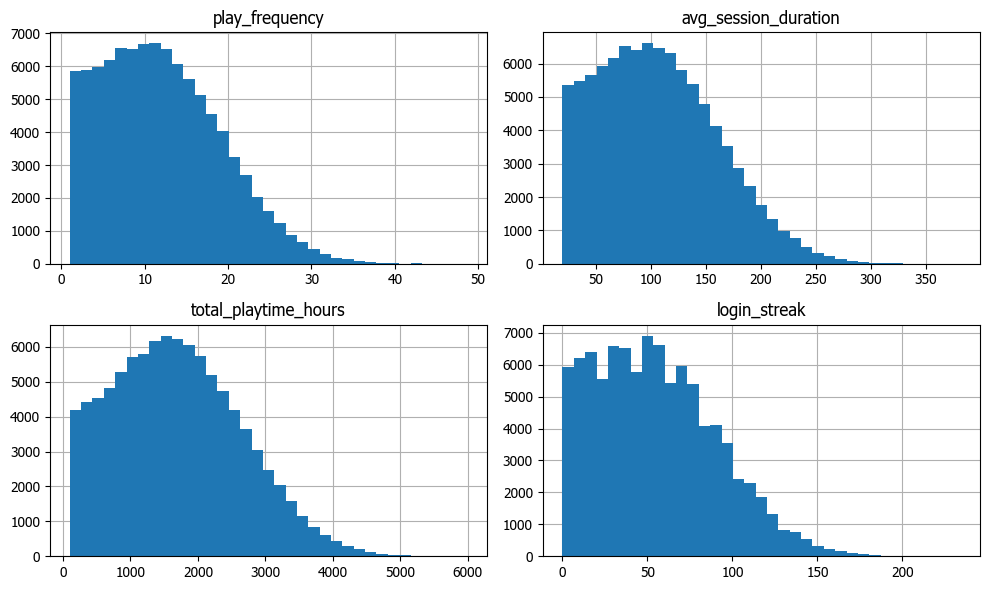

In [5]:
display(features.describe(include='all').T.head(12))
features[['play_frequency', 'avg_session_duration', 'total_playtime_hours', 'login_streak']].hist(bins=35, figsize=(10, 6))
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** ข้อมูลตัวเลขมี 34 feature; `play_frequency` median=11.420, p99=30.504; `avg_session_duration` median=102.452, p99=246.651; `total_playtime_hours` median=1,635.500, p99=4,063.774; `login_streak` median=52.000, p99=147.000

**Interpretation:** ช่วงและรูปทรงของ feature ต่างกัน จึงต้องอ่านแกนและหน่วยก่อนเปรียบเทียบ

**ML Implications:** Tree baseline ไม่ต้อง scale; หากเปลี่ยนเป็น linear/distance model ให้ scale ภายใน fold

**Recommended Action:** ตรวจ target และความสัมพันธ์กับ feature เพิ่มเพื่อเลือกการแปลงข้อมูล

,count,pct
segment,,
0,40934,39.3596
1,26034,25.0327
2,21014,20.2058
3,16018,15.4019


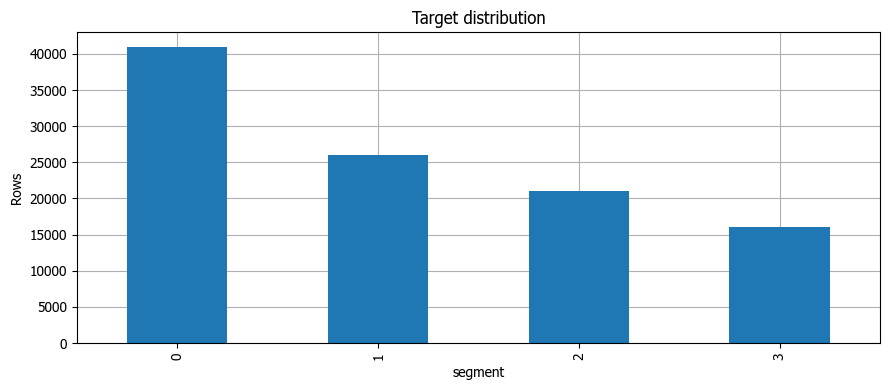

In [6]:
if target == 'spending_30d':
    display(frame[target].describe(percentiles=[.5, .9, .95, .99]).to_frame())
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    frame[target].hist(bins=50, ax=axes[0])
    axes[0].set_title('Spending (THB)')
    np.log1p(frame[target]).hist(bins=50, ax=axes[1])
    axes[1].set_title('log1p spending')
else:
    counts = frame[target].value_counts(dropna=False).sort_index()
    display(pd.DataFrame({'count': counts, 'pct': counts / len(frame) * 100}))
    counts.plot.bar(title='Target distribution', ylabel='Rows')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** จำนวน label แต่ละคลาสคือ {0: 40934, 1: 26034, 2: 21014, 3: 16018}; target หาย 0 แถว

**Interpretation:** คลาสมีจำนวนไม่เท่ากัน ต้องระวัง accuracy ที่กลบผลของคลาสเล็ก

**ML Implications:** ใช้ stratified validation และตรวจ F1 รายคลาส; class weight ต้องประเมินจาก validation

**Recommended Action:** ใช้เฉพาะ label ที่สังเกตได้และรายงาน metric หลายมุม

## 5. Feature Relationships

,eta_squared
vip_tier,0.1599
spending_frequency,0.1225
avg_monthly_spending,0.1219
days_since_last_login,0.1146
rare_items_count,0.0942
total_spending_thb,0.0757
total_playtime_hours,0.0711
friend_count,0.0629
avg_session_duration,0.0572
gifts_sent_received,0.0564


pearson_r
avg_monthly_spending vip_tier                  0.1560
spending_frequency   vip_tier                  0.1507
rare_items_count     vip_tier                  0.1365
avg_monthly_spending spending_frequency        0.1316
                     rare_items_count          0.1183
total_spending_thb   vip_tier                  0.1176
spending_frequency   rare_items_count          0.1158
total_spending_thb   spending_frequency        0.1081
                     avg_monthly_spending      0.1028
total_playtime_hours days_since_last_login    -0.0982

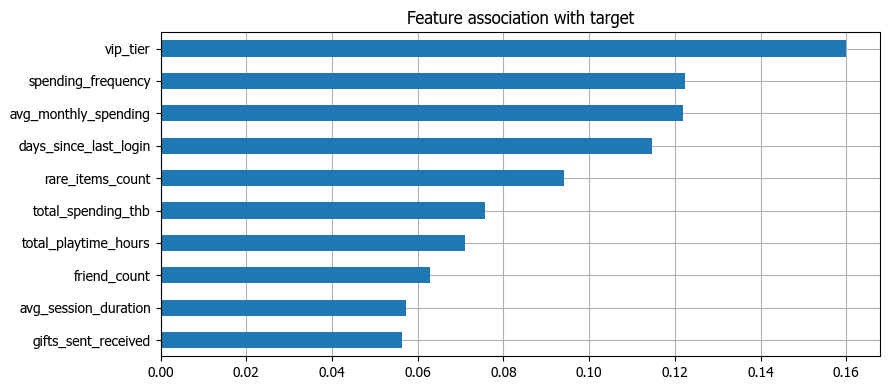

In [7]:
relevance = association(frame, target, regression=False)
display(relevance.head(12).rename('abs_spearman' if target == 'spending_30d' else 'eta_squared').to_frame())
display(strongest_pairs(features).rename('pearson_r').to_frame())
relevance.head(10).sort_values().plot.barh(title='Feature association with target')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Feature ที่มี association สูงสุดคือ `vip_tier` = 0.1599 (eta squared; ไม่สมมติลำดับคลาส); คู่ feature ที่มี |Pearson r| สูงสุดคือ ('avg_monthly_spending', 'vip_tier') r=0.1560

**Interpretation:** ความสัมพันธ์คำนวณบนคู่ที่ไม่ missing ไม่ได้แสดงเหตุและผลหรือยืนยัน leakage

**ML Implications:** หลีกเลี่ยงใช้ correlation ของรหัส multiclass เป็นตัวชี้วัดหลัก; ยังไม่เลือก feature ด้วย validation ชุดสุดท้าย

**Recommended Action:** ตรวจ class-conditional patterns และเวลาที่ feature ถูกสร้างก่อน target

### Feature interactions

In [8]:
interaction_data = frame.assign(
    spending_bin=pd.qcut(frame.total_spending_thb, 4, duplicates='drop'),
    frequency_bin=pd.qcut(frame.play_frequency, 4, duplicates='drop'),
    whale=frame.segment.eq(3).astype(float),
)
interaction = interaction_data.pivot_table(index='spending_bin', columns='frequency_bin',
                                          values='whale', aggfunc='mean', observed=True)
display(interaction)
display(pd.crosstab(interaction_data.spending_bin, interaction_data.frequency_bin))

frequency_bin,"(0.999, 6.464]","(6.464, 11.42]","(11.42, 16.865]","(16.865, 48.7]"
spending_bin,,,,
"(500.473, 16335.228]",0.0485,0.0613,0.0805,0.1119
"(16335.228, 31572.321]",0.0727,0.0904,0.1197,0.1594
"(31572.321, 49016.415]",0.1032,0.1415,0.1669,0.2394
"(49016.415, 144500.577]",0.1770,0.2341,0.2855,0.3645


frequency_bin,"(0.999, 6.464]","(6.464, 11.42]","(11.42, 16.865]","(16.865, 48.7]"
spending_bin,,,,
"(500.473, 16335.228]",5730,5581,5465,5461
"(16335.228, 31572.321]",5581,5564,5563,5476
"(31572.321, 49016.415]",5464,5541,5638,5513
"(49016.415, 144500.577]",5384,5437,5545,5802


**Findings & Interpretation**

**Findings:** ตาราง interaction มี 4×4 ช่อง; ค่าที่สังเกตได้ต่ำสุด 0.0485, สูงสุด 0.3645

**Interpretation:** ตารางแสดงสัดส่วน Whale ตาม spending และ play frequency ร่วมกัน ไม่สมมติว่า segment เป็นเลขต่อเนื่อง; ช่วง bin มาจาก quartile ของข้อมูลที่ใช้วิเคราะห์ และบางช่องอาจมีตัวอย่างน้อย

**ML Implications:** Tree model รองรับความสัมพันธ์ร่วมแบบนี้ได้; ยังไม่สร้างกฎตัดสินจาก EDA เพียงอย่างเดียว

**Recommended Action:** อ่านจำนวนตัวอย่างในแต่ละช่องก่อนตีความ และตรวจผลบน validation แยกจาก EDA

## 6. Task-Specific EDA

In [9]:
display(frame.groupby(target)[['play_frequency', 'total_spending_thb', 'friend_count']].median())
display(pd.crosstab(frame['player_type_tag'], frame[target], normalize='columns'))
display(relevance.reindex(['random_metric_1', 'random_metric_2', 'random_metric_3']).to_frame())
unseen = {column: sorted(set(test[column].dropna()) - set(train[column].dropna()))
          for column in features.select_dtypes(include=['object', 'str'])}
print('Unseen test categories:', unseen)

Unseen test categories: {'region': [], 'platform': [], 'device_type': [], 'payment_method': [], 'language': [], 'account_status': [], 'player_type_tag': [], 'engagement_level': [], 'loyalty_tier': [], 'skill_tier': []}


,play_frequency,total_spending_thb,friend_count
segment,,,
0,9.8576,"26,099.5393",87.0000
1,13.4360,"28,416.7124",124.0000
2,10.2578,"37,728.8790",91.0000
3,13.9558,"45,023.8358",127.0000


segment,0,1,2,3
player_type_tag,,,,
Casual,0.2529,0.2459,0.2492,0.2527
Collector,0.2506,0.2516,0.2595,0.2497
Competitive,0.2506,0.2476,0.2429,0.2457
Social,0.2459,0.2549,0.2484,0.2519


,eta_squared
random_metric_1,0.0000
random_metric_2,0.0000
random_metric_3,0.0001


**Findings & Interpretation**

**Findings:** Noise feature มี eta squared {'random_metric_1': 8e-06, 'random_metric_2': 2.6e-05, 'random_metric_3': 5.9e-05}; ค่า association สูงสุดของ feature ทั้งหมด 0.1599

**Interpretation:** data card ระบุ noise ไว้ชัดเจน; ความต่างของกลุ่มและ tag ยังไม่ยืนยันกระบวนการสร้าง target

**ML Implications:** ตัด random_metric_1–3 จาก baseline; เข้ารหัส category โดยรองรับ unseen และ missing

**Recommended Action:** ตรวจ provenance ของ player_type_tag, engagement_level และ loyalty_tier ก่อนใช้งานจริง

## 7. EDA Findings & Insights

- Feature missing เฉลี่ย 8.63% และมีค่าที่อยู่นอกช่วงตรวจ 144,311 จุด
- Duplicate feature rows 0 แถว
- Train มี target ที่ทราบค่า 104,000 จาก 104,000 แถว
- ความสัมพันธ์เป็น observed association; leakage และสาเหตุของค่าผิดช่วงยังเป็นประเด็นที่ต้องตรวจ

## 8. Preprocessing Recommendations

- ไม่ใช้ player_id เป็น predictor และไม่เติม target ที่หาย
- Fit imputer/encoder เฉพาะ training fold; HistGradientBoosting รองรับ NaN ใน numerical features
- ยังไม่ลบ IQR outlier อัตโนมัติ เพราะอาจเป็นกลุ่มพฤติกรรมที่ต้องการทำนาย
- ใช้ categorical-aware encoding และตัด noise feature ที่ระบุใน data card
- Tree model ไม่จำเป็นต้อง scale; ถ้าใช้ linear/distance model ให้ scale ภายใน fold

## 9. Baseline Model Recommendations

เริ่ม HistGradientBoostingClassifier พร้อม categorical features แบ่ง stratified holdout 80/20 seed 42 ตรวจ macro F1 และ accuracy รายคลาส

การฝึกโมเดลอยู่ใน `../02_baseline_submission.ipynb` ไม่มีการ fit ใน EDA notebook นี้

## 10. Final EDA Summary

ยืนยันจากข้อมูลในเครื่อง: 104,000 แถวที่ใช้วิเคราะห์, 44 feature, missing เฉลี่ย 8.63% และ known labels 104,000 แถว

ขั้นถัดไปคือรัน baseline แยกจาก EDA ตรวจ prediction และเก็บ local validation ก่อนปรับโมเดลให้ยืนยัน metric ทางการ วิธีจับคู่แถว submission และ provenance ของ feature ยังไม่สามารถพิสูจน์ temporal leakage หรือสาเหตุที่ข้อมูลบางค่าหลุดช่วงจากไฟล์ปัจจุบันได้